# Chapitre 13 - Exercices 13.5 à 13.8

* **13.5** : meilleure approximation de rang $L$ d'une famille de matrices (réduction de
  dimension globale, éq. (13.11)).
* **13.6** : moyenne de formes invariante par transformation affine.
* **13.7** : k-ppv sur les problèmes « facile » et « difficile » ; validation croisée contre
  pénalisation de type AIC.
* **13.8** : invariance par rotation : k-ppv, « hints », métrique invariante, distance
  tangente.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.special import i0e
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import ch13_prototypes as cp
set_style()
PURPLE = COLORS[6]

## Exercice 13.5 : Meilleure approximation de rang $L$

**Énoncé (reformulé).** Soient $B_1, \dots, B_N$ des matrices $p \times p$ symétriques
semi-définies positives et $\bar B = \frac1N\sum_i B_i$, de décomposition spectrale
$\bar B = \sum_{\ell=1}^p \theta_\ell e_\ell e_\ell^T$ avec $\theta_1 \ge \theta_2 \ge \dots \ge \theta_p$.
Montrer que la meilleure approximation de rang $L$ des $B_i$,
$$\min_{\operatorname{rang}(M) = L} \ \sum_{i=1}^N \operatorname{trace}\big[(B_i - M)^2\big],$$
est donnée par $\bar B_{[L]} = \sum_{\ell=1}^L \theta_\ell e_\ell e_\ell^T$.
*Indication* : écrire $\sum_i \operatorname{trace}[(B_i - M)^2]$ comme
$\sum_i \operatorname{trace}[(B_i - \bar B)^2] + \sum_i \operatorname{trace}[(M - \bar B)^2]$.

(Le livre ordonne les valeurs propres avec une coquille d'indice ; nous les prenons
décroissantes.)

### Rappels

* **Produit scalaire de Frobenius** : $\langle A, C\rangle = \operatorname{trace}(A^TC)$,
  de norme $\|A\|_F^2 = \sum_{jk} A_{jk}^2$. Pour $A$ **symétrique**,
  $\operatorname{trace}(A^2) = \operatorname{trace}(A^TA) = \|A\|_F^2$. Nous cherchons donc
  $M$ symétrique (c'est naturel, et c'est nécessaire pour que le critère soit une somme de
  carrés).
* **Théorème spectral** : une matrice symétrique réelle se diagonalise dans une base
  orthonormée de vecteurs propres.
* La trace est linéaire et **invariante par changement de base orthonormée** :
  $\operatorname{trace}(U^TAU) = \operatorname{trace}(A)$ si $U$ est orthogonale.

### Étape 1 : décomposition « biais–variance » (l'indication)

On écrit $B_i - M = (B_i - \bar B) + (\bar B - M)$ et on développe le carré (pour des
matrices symétriques, $\operatorname{trace}((X + Y)^2) = \operatorname{trace}(X^2) + 2\operatorname{trace}(XY) + \operatorname{trace}(Y^2)$,
car $\operatorname{trace}(XY) = \operatorname{trace}(YX)$) :
$$\sum_i \operatorname{trace}[(B_i - M)^2] = \sum_i \operatorname{trace}[(B_i - \bar B)^2]
+ 2\operatorname{trace}\Big[\Big(\sum_i (B_i - \bar B)\Big)(\bar B - M)\Big] + N\operatorname{trace}[(\bar B - M)^2].$$
Par définition de la moyenne, $\sum_i (B_i - \bar B) = 0$ : le terme croisé disparaît.
Le premier terme ne dépend pas de $M$. Le problème revient donc à
$$\min_{\operatorname{rang}(M) \le L} \|\bar B - M\|_F^2 .$$

### Étape 2 : un lemme sur les traces (Ky Fan)

**Lemme.** Soit $C$ symétrique de valeurs propres $\lambda_1 \ge \dots \ge \lambda_p$
(vecteurs propres orthonormés $e_j$), et $q_1, \dots, q_L$ des vecteurs orthonormés. Alors
$\sum_{i=1}^L q_i^T C q_i \le \lambda_1 + \dots + \lambda_L$.

*Preuve.* Décomposons dans la base propre : $q_i^T C q_i = \sum_j \lambda_j (e_j^T q_i)^2$.
Donc $\sum_i q_i^TCq_i = \sum_j \lambda_j w_j$ avec $w_j = \sum_i (e_j^Tq_i)^2$.
* $w_j \le 1$ : c'est le carré de la norme de la projection de $e_j$ sur
  $\operatorname{vect}(q_1, \dots, q_L)$, inférieur à $\|e_j\|^2 = 1$ ;
* $\sum_j w_j = \sum_i \|q_i\|^2 = L$ (Pythagore dans la base $e_j$).

Maximiser $\sum_j \lambda_j w_j$ sous $0 \le w_j \le 1$, $\sum_j w_j = L$ revient à mettre
tout le poids possible sur les plus grandes valeurs : le maximum vaut
$\lambda_1 + \dots + \lambda_L$ (prendre $w_1 = \dots = w_L = 1$). $\square$

### Étape 3 : minoration et cas d'égalité

Soit $M$ de rang $\le L$ et $Q$ le projecteur orthogonal sur un sous-espace de dimension
$L$ contenant l'image de $M$ ; $Q = \sum_{i=1}^L q_iq_i^T$ avec des $q_i$ orthonormés, et
$(I - Q)M = 0$. Par Pythagore (les colonnes de $Q X$ et $(I-Q)X$ sont orthogonales),
$$\|\bar B - M\|_F^2 \ge \|(I - Q)(\bar B - M)\|_F^2 = \|(I - Q)\bar B\|_F^2
= \operatorname{trace}(\bar B^2) - \operatorname{trace}(Q \bar B^2 Q),$$
en développant $\operatorname{trace}(\bar B(I-Q)^2\bar B)$ avec $(I-Q)^2 = I - Q$. Or
$\operatorname{trace}(Q\bar B^2Q) = \sum_i q_i^T \bar B^2 q_i \le \theta_1^2 + \dots + \theta_L^2$
par le lemme appliqué à $C = \bar B^2$, dont les valeurs propres sont les $\theta_\ell^2$,
**dans le même ordre** car $\theta_\ell \ge 0$ ($\bar B$ est semi-définie positive, comme
moyenne de matrices qui le sont). D'où, avec $\operatorname{trace}(\bar B^2) = \sum_\ell \theta_\ell^2$,
$$\|\bar B - M\|_F^2 \ge \sum_{\ell > L} \theta_\ell^2 .$$
Enfin, $\bar B - \bar B_{[L]} = \sum_{\ell > L}\theta_\ell e_\ell e_\ell^T$ a exactement pour norme
au carré $\sum_{\ell > L}\theta_\ell^2$ : la borne est atteinte par $M = \bar B_{[L]}$. $\square$

### Vérification numérique

On tire $N = 30$ matrices $B_i$ semi-définies positives de rang 2 (comme des matrices
inter-classes locales), et on compare le critère en $\bar B_{[L]}$ à celui obtenu par
optimisation numérique directe sur les matrices symétriques de rang $L$
($M = U\operatorname{diag}(d)U^T$, $U$ de taille $p \times L$), depuis 20 points de départ.

In [2]:
rng = np.random.RandomState(0)
p, N, L = 6, 30, 2
Bs = []
for _ in range(N):
    G = rng.randn(p, 2) * np.array([3, 2, 1, 0.5, 0.3, 0.2])[:, None]
    Bs.append(G @ G.T)
Bs = np.array(Bs)
Bbar = Bs.mean(0)


def crit(M):
    return sum(np.trace((B - M) @ (B - M)) for B in Bs)


theta, E = np.linalg.eigh(Bbar)
theta, E = theta[::-1], E[:, ::-1]
B_L = (E[:, :L] * theta[:L]) @ E[:, :L].T
best = crit(B_L)


def obj(v):
    U = v[:p * L].reshape(p, L)
    return crit((U * v[p * L:]) @ U.T)


found = [minimize(obj, rng.randn(p * L + L), method="BFGS").fun for _ in range(20)]
print("critère en B̄_[L]                  : %.4f" % best)
print("meilleur critère trouvé numériquement : %.4f" % min(found))
print("formule  N*sum_{l>L} theta_l^2 + sum_i ||B_i - B̄||² : %.4f"
      % (N * (theta[L:] ** 2).sum() + sum(np.trace((B - Bbar) @ (B - Bbar)) for B in Bs)))

critère en B̄_[L]                  : 18035.5601
meilleur critère trouvé numériquement : 18035.5601
formule  N*sum_{l>L} theta_l^2 + sum_i ||B_i - B̄||² : 18035.5601


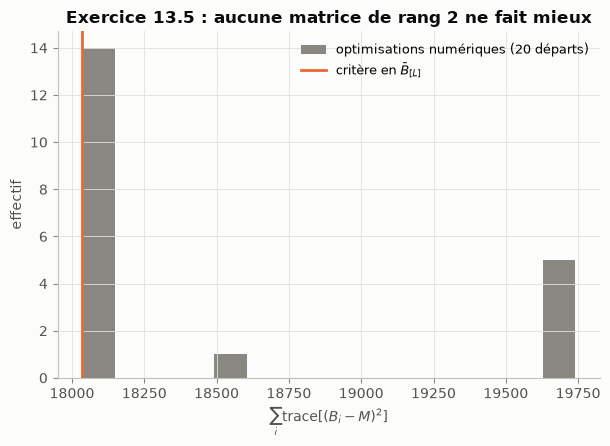

In [3]:
fig, ax = plt.subplots()
ax.hist(found, bins=15, color=GRAY, label="optimisations numériques (20 départs)")
ax.axvline(best, color=ORANGE, lw=2, label="critère en $\\bar B_{[L]}$")
ax.set(title="Exercice 13.5 : aucune matrice de rang 2 ne fait mieux",
       xlabel="$\\sum_i \\mathrm{trace}[(B_i - M)^2]$", ylabel="effectif")
ax.legend()
plt.show()

> **À retenir.** Grâce à la décomposition « autour de la moyenne », approcher au mieux
> toute une famille $B_i$ par une matrice de rang $L$ revient à approcher leur moyenne
> $\bar B$ ; la solution est la troncature spectrale (théorème d'Eckart–Young, démontré
> ici via l'inégalité de Ky Fan). C'est la justification de la réduction de dimension
> globale de la section 13.4.2.

## Exercice 13.6 : Moyenne de formes

**Énoncé (reformulé).** Les $L_j$, $j = 1, \dots, M$, sont des matrices $N \times 2$ de
points du plan, échantillonnés aux mêmes positions sur des lettres manuscrites (cursives).
On cherche une moyenne $V$ ($N \times 2$, avec $V^TV = I$) **invariante par transformation
affine**, qui minimise
$$\sum_{j=1}^M \min_{A_j} \|L_j - VA_j\|^2 .$$
Caractériser la solution. Cette solution peut souffrir de quelques grandes lettres qui
dominent la moyenne ; on propose plutôt de minimiser
$$\sum_{j=1}^M \min_{A_j} \|L_jA_j - V\|^2 .$$
Dériver la solution. En quoi les deux critères diffèrent-ils ? Utiliser la SVD des $L_j$
pour simplifier la comparaison.

### Rappels et conventions

* $\|X\|^2 = \|X\|_F^2 = \operatorname{trace}(X^TX)$ ; les $A_j$ sont des matrices $2 \times 2$
  quelconques (transformation linéaire du plan). Nous supposons les lettres **centrées**
  (moyenne de chaque colonne nulle), ce qui élimine les translations.
* **Moindres carrés matriciels** : pour $X$ de taille $N \times 2$ de rang 2,
  $\min_A \|Y - XA\|^2$ est atteint en $A = (X^TX)^{-1}X^TY$, et $X(X^TX)^{-1}X^T$ est le
  **projecteur orthogonal** sur l'espace engendré par les colonnes de $X$.
* **SVD** : $L_j = U_jD_jW_j^T$ avec $U_j$ ($N \times 2$) à colonnes orthonormées, $D_j$
  diagonale positive, $W_j$ orthogonale $2 \times 2$.
* Le lemme de Ky Fan de l'exercice 13.5 : $\max_{V^TV = I}\operatorname{trace}(V^TCV)$ est
  la somme des 2 plus grandes valeurs propres de $C$, atteinte pour $V$ formée des 2
  premiers vecteurs propres.

### Premier critère

À $V$ fixé ($V^TV = I$), le problème en $A_j$ est un moindre carré :
$A_j = (V^TV)^{-1}V^TL_j = V^TL_j$. Le résidu est la projection de $L_j$ sur l'orthogonal
de $\operatorname{vect}(V)$, et par Pythagore
$$\min_{A_j}\|L_j - VA_j\|^2 = \|L_j\|^2 - \|VV^TL_j\|^2 = \|L_j\|^2 - \operatorname{trace}(V^TL_jL_j^TV).$$
Minimiser la somme revient à **maximiser** $\operatorname{trace}\big(V^T C_1 V\big)$ avec
$$C_1 = \sum_j L_jL_j^T = \sum_j U_j D_j^2 U_j^T .$$
La solution : $V$ = les **deux premiers vecteurs propres** de $C_1$ (matrice $N \times N$).
C'est une ACP des lettres empilées.

### Second critère

À $V$ fixé, le moindre carré en $A_j$ donne $A_j = (L_j^TL_j)^{-1}L_j^TV$, et avec le
projecteur $H_j = L_j(L_j^TL_j)^{-1}L_j^T$ :
$$\min_{A_j}\|L_jA_j - V\|^2 = \|V\|^2 - \operatorname{trace}(V^TH_jV) = 2 - \operatorname{trace}(V^TH_jV),$$
car $\|V\|^2 = \operatorname{trace}(V^TV) = 2$. On maximise donc $\operatorname{trace}(V^TC_2V)$ avec
$$C_2 = \sum_j H_j = \sum_j U_jU_j^T,$$
en utilisant la SVD : $L_j(L_j^TL_j)^{-1}L_j^T = U_jD_jW_j^T(W_jD_j^{-2}W_j^T)W_jD_jU_j^T = U_jU_j^T$.
Solution : $V$ = les deux premiers vecteurs propres de $C_2$.

(La contrainte $V^TV = I$ est indispensable : sans elle, $V = 0$ et $A_j = 0$ donneraient
un critère nul.)

### Comparaison

* Les deux solutions sont des vecteurs propres d'une somme de « contributions » des
  lettres : $U_jD_j^2U_j^T$ pour le premier critère, $U_jU_j^T$ pour le second.
* Dans le premier, chaque lettre pèse selon $D_j^2$, c'est-à-dire **le carré de sa
  taille** (et de son allongement) : une lettre 10 fois plus grande pèse 100 fois plus.
* Dans le second, chaque lettre ne contribue que par le **sous-espace** engendré par ses
  colonnes (le projecteur $U_jU_j^T$), qui est inchangé si l'on remplace $L_j$ par $L_jB$
  pour toute $B$ inversible : le critère est **vraiment invariant affine** et toutes les
  lettres ont le même poids.

### Illustration numérique

Une « lettre » de référence (une boucle cursive, en forme de « e » : une cycloïde allongée
$x = t - 1{,}8\sin t$, $y = 1 - 1{,}8\cos t$) est échantillonnée en $N = 60$ points.
On fabrique 20 copies : chacune subit une transformation affine aléatoire et un petit
bruit. On ajoute 3 lettres **très grandes** (échelle 15) et **mal formées** (bruit fort et
déformation non affine). On compare les deux moyennes à la forme de référence.

In [4]:
rng = np.random.RandomState(0)
Npts = 60
t = np.linspace(-0.6, 2 * np.pi + 0.6, Npts)
ref = np.column_stack([t - 1.8 * np.sin(t), 1 - 1.8 * np.cos(t)])   # une boucle cursive (« e »)


def center(Lm):
    return Lm - Lm.mean(0)


letters = []
for j in range(20):
    A = np.eye(2) + 0.4 * rng.randn(2, 2)
    letters.append(center((ref + 0.05 * rng.randn(Npts, 2)) @ A))
for j in range(3):
    bad = ref + np.column_stack([1.2 * np.sin(1.5 * t + j), 1.0 * np.cos(t)]) + 0.3 * rng.randn(Npts, 2)
    letters.append(center(15 * bad @ (np.eye(2) + 0.3 * rng.randn(2, 2))))
letters = np.array(letters)


def top2(C):
    vals, vecs = np.linalg.eigh(C)
    return vecs[:, ::-1][:, :2]


V1 = top2(sum(Lm @ Lm.T for Lm in letters))
V2 = top2(sum(Lm @ np.linalg.solve(Lm.T @ Lm, Lm.T) for Lm in letters))


def subspace_gap(V, X):
    """Distance entre l'espace des colonnes de V et celui de X (projecteurs)."""
    P1 = V @ V.T
    Q, _ = np.linalg.qr(X)
    return np.linalg.norm(P1 - Q @ Q.T)


ref_c = center(ref)
print("écart au sous-espace de la référence : critère 1 = %.3f, critère 2 = %.3f"
      % (subspace_gap(V1, ref_c), subspace_gap(V2, ref_c)))

écart au sous-espace de la référence : critère 1 = 1.110, critère 2 = 0.055


Pour **afficher** une moyenne $V$ (définie à une transformation affine près), on la
ramène sur la référence par moindres carrés : $V\hat A$ avec $\hat A = \arg\min_A \|VA - \text{réf}\|^2$.

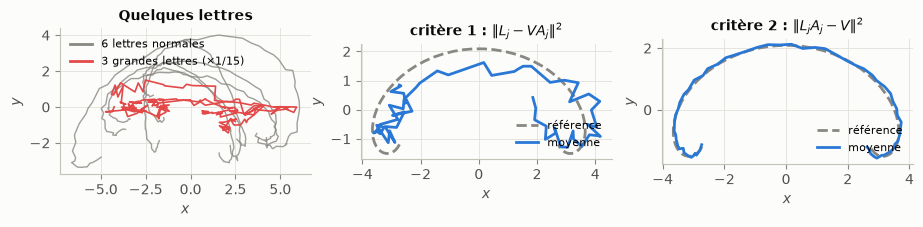

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
for Lm in letters[:6]:
    axes[0].plot(*Lm.T, color=GRAY, lw=1, alpha=0.8)
for Lm in letters[20:]:
    axes[0].plot(*(Lm / 15).T, color=COLORS[7], lw=1.2)
axes[0].plot([], [], color=GRAY, label="6 lettres normales")
axes[0].plot([], [], color=COLORS[7], label="3 grandes lettres (×1/15)")
axes[0].legend(fontsize=8)
axes[0].set_title("Quelques lettres", fontsize=10)
for ax, V, name in [(axes[1], V1, "critère 1 : $\\|L_j - VA_j\\|^2$"),
                    (axes[2], V2, "critère 2 : $\\|L_jA_j - V\\|^2$")]:
    A_hat = np.linalg.lstsq(V, ref_c, rcond=None)[0]
    Vd = V @ A_hat
    ax.plot(*ref_c.T, "--", color=GRAY, label="référence")
    ax.plot(*Vd.T, color=BLUE, label="moyenne")
    ax.set_title(name, fontsize=10)
    ax.legend(fontsize=8, loc="lower right")
for ax in axes:
    ax.set(aspect="equal", xlabel="$x$", ylabel="$y$")
plt.show()

Le premier critère est capturé par les trois grandes lettres mal formées ; le second,
qui donne le même poids à chaque lettre, retrouve la forme de référence.

> **À retenir.** Les deux moyennes sont les vecteurs propres dominants d'une somme
> $\sum_j U_j\,\Lambda_j\,U_j^T$ ; le premier critère prend $\Lambda_j = D_j^2$ (les grandes
> lettres dominent), le second $\Lambda_j = I$ (invariance affine complète, chaque lettre
> ne compte que par son sous-espace).

## Exercice 13.7 : k-ppv sur les problèmes « facile » et « difficile »

**Énoncé (reformulé).** On applique les plus proches voisins aux problèmes « facile » et
« difficile » de la figure 13.5 (panneau de gauche).

1. Reproduire les résultats du panneau de gauche de la figure 13.5.
2. Estimer les erreurs de classification par validation croisée à 5 blocs, et comparer
   les courbes d'erreur à celles de la question 1.
3. Considérer une pénalisation « de type AIC » de l'erreur d'apprentissage : on lui ajoute
   $2t/N$, où $t \approx N/r$ est le nombre approximatif de paramètres, $r$ étant le nombre
   de voisins. Comparer les courbes de cette erreur pénalisée à celles des questions 1
   et 2. Quelle méthode estime le mieux le nombre optimal de voisins : la validation
   croisée ou l'AIC ?

### Rappels

* Données (éq. (13.6) du livre) : $X$ uniforme sur $[0, 1]^{10}$ ; « facile » :
  $Y = \mathbb 1\{X_1 > 1/2\}$ ; « difficile » : $Y = \mathbb 1\{\prod_{j\le 3}(X_j - 1/2) > 0\}$.
  100 points d'apprentissage, 1000 points test, 10 réalisations.
* **Validation croisée à 5 blocs** : on découpe l'échantillon en 5 parts ; chaque part est
  prédite par le modèle appris sur les 4 autres ; on moyenne les erreurs.
* **AIC** (chapitre 7) : erreur d'apprentissage $+\ 2\,d/N\,\hat\sigma^2$, où $d$ est le nombre de
  paramètres. Pour le k-ppv, le nombre effectif de paramètres est $N/r$ (autant que de
  voisinages disjoints), d'où le critère $\overline{\mathrm{err}} + 2(N/r)/N = \overline{\mathrm{err}} + 2/r$.
  L'erreur d'apprentissage est calculée en comptant le point lui-même parmi ses voisins
  (elle est nulle pour $r = 1$).

In [6]:
ks = np.arange(1, 62, 2)
n_rep = 10
out = {pb: {"test": [], "cv": [], "train": []} for pb in ("easy", "hard")}
for pb in ("easy", "hard"):
    for rep in range(n_rep):
        rng = np.random.RandomState(100 + rep)
        X, y = cp.simulate_easy_hard(100, pb, rng=rng)
        Xt, yt = cp.simulate_easy_hard(1000, pb, rng=rng)
        out[pb]["test"].append((cp.knn_from_dists(cp.sq_dists(Xt, X), y, ks, rng) != yt).mean(1))
        out[pb]["train"].append((cp.knn_from_dists(cp.sq_dists(X, X), y, ks, rng) != y).mean(1))
        out[pb]["cv"].append(cp.knn_cv_error(X, y, ks, n_folds=5, rng=rng)[0])
    for key in out[pb]:
        out[pb][key] = np.array(out[pb][key])
    out[pb]["aic"] = out[pb]["train"] + 2.0 / ks

### Question 1 : le panneau de gauche de la figure 13.5